# Eksperimen dan evaluasi PhiUSIIL

Jalankan notebook audit terlebih dahulu. Eksperimen utama mengikuti PDF penelitian. **A** memakai fitur leksikal dan halaman pada split acak. **B** memakai fitur leksikal pada split acak yang sama. **C** memakai fitur leksikal pada domain terpisah. B − A mengukur perubahan cakupan fitur pada baris uji yang sama. C − B mengukur perubahan protokol bersama perubahan komposisi data uji.

Analisis pembobotan tambahan mengikuti proposal P1 lokal. Baseline, bobot kelas, dan bobot kelompok struktur memakai split dan fitur C.

In [1]:
from importlib.metadata import version
from pathlib import Path
from statistics import median
from time import perf_counter
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

OUT = Path("hasil")
manifest = json.loads((OUT / "manifest_data.json").read_text(encoding="utf-8"))
data = pd.read_csv(OUT / "fitur_internal.csv.gz")
SEED = manifest["seed"]
LEXICAL = manifest["fitur_leksikal"]
PAGE = manifest["fitur_halaman"]
GROUPS = ("akar", "path", "query")
FPR_LIMIT = .01
MIN_SUPPORT = 30
BATCH = 1024
PARAMS = {
    "LR": dict(max_iter=1000, random_state=SEED),
    "RF": dict(n_estimators=60, max_depth=16, min_samples_leaf=3, random_state=SEED, n_jobs=1),
}

## Pelatihan dan ambang

Imputasi median dan standardisasi untuk LR dipelajari pada data latih. Model memakai parameter tetap. Ambang utama memaksimalkan F1 validasi. Pada analisis pembobotan, ambang memaksimalkan recall validasi dengan FPR maksimal 1%. Jika nilai objektif sama, pilih FPR terendah lalu ambang tertinggi.

Waktu inferensi adalah median lima pengukuran untuk batch tetap 1.024 baris setelah pemanasan, dengan satu thread. Pengukuran mencakup praproses pipeline dan prediksi probabilitas. Ekstraksi fitur dilakukan sebelumnya.

In [2]:
def choose_threshold(y, scores, fpr_limit):
    order = np.argsort(-scores, kind="stable")
    score, target = scores[order], y[order]
    ends = np.r_[np.flatnonzero(score[:-1] != score[1:]), len(y)-1]
    thresholds = np.r_[np.nextafter(score[0], np.inf), score[ends]]
    tp = np.r_[0, np.cumsum(target)[ends]]
    fp = np.r_[0, ends+1] - tp
    positives = y.sum()
    fpr = fp / (len(y)-positives)
    if fpr_limit is None:
        goal, allowed = 2*tp/(positives+tp+fp), np.arange(len(tp))
    else:
        goal, allowed = tp/positives, np.flatnonzero(fpr <= fpr_limit)
    best = max(allowed, key=lambda i: (goal[i], -fpr[i], thresholds[i]))
    return float(thresholds[best])

def metrics(y, scores, threshold):
    tn, fp, fn, tp = confusion_matrix(y, scores >= threshold, labels=[0, 1]).ravel()
    pos, neg = tp+fn, tn+fp
    return dict(tn=tn, fp=fp, fn=fn, tp=tp, phishing=pos, sah=neg,
                precision=tp/(tp+fp) if tp+fp else 0.0,
                recall=tp/pos if pos else np.nan, fpr=fp/neg if neg else np.nan,
                f1=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0,
                roc_auc=roc_auc_score(y, scores) if pos and neg else np.nan)

def sample_weights(train, strategy):
    y = train["phishing"].to_numpy()
    weights = len(y) / (2*np.bincount(y)[y])
    if strategy == "bobot_struktur":
        positive = y == 1
        groups = train["struktur"].to_numpy()[positive]
        counts = pd.Series(groups).value_counts()
        assert set(counts.index) == set(GROUPS)
        total = weights[positive].sum()
        weights[positive] = [total / (len(GROUPS)*counts[group]) for group in groups]
        assert np.isclose(weights[positive].sum(), total)
    return weights

def fit_and_score(name, split, columns, strategy):
    train, val, test = (data.loc[data[split] == part] for part in ("latih", "validasi", "uji"))
    if name == "LR":
        model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              LogisticRegression(**PARAMS[name]))
    else:
        model = make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(**PARAMS[name]))
    fit_args = {}
    if strategy != "tanpa_bobot":
        fit_args[f"{model.steps[-1][0]}__sample_weight"] = sample_weights(train, strategy)

    with threadpool_limits(limits=1):
        model.fit(train[columns], train["phishing"], **fit_args)
        batch = test[columns].sample(n=BATCH, random_state=SEED)
        model.predict_proba(batch)
        times = []
        for _ in range(5):
            start = perf_counter()
            model.predict_proba(batch)
            times.append((perf_counter()-start)*1000)
        val_scores = model.predict_proba(val[columns])[:, 1]
        test_scores = model.predict_proba(test[columns])[:, 1]
    return val, test, val_scores, test_scores, median(times)

def evaluate(name, scenario, fitted, fpr_limit=None):
    val, test, val_scores, test_scores, elapsed = fitted
    val_y, test_y = val["phishing"].to_numpy(), test["phishing"].to_numpy()
    threshold = choose_threshold(val_y, val_scores, fpr_limit)
    val_metrics = metrics(val_y, val_scores, threshold)
    if fpr_limit is not None:
        assert val_metrics["fpr"] <= fpr_limit
    by_group = []
    for group in GROUPS:
        mask = test["struktur"].to_numpy() == group
        scores = metrics(test_y[mask], test_scores[mask], threshold)
        by_group.append(dict(model=name, skenario=scenario, struktur=group,
                             layak_recall_min=scores["phishing"] >= MIN_SUPPORT, **scores))
    eligible = [row for row in by_group if row["layak_recall_min"]]
    worst = min(eligible, key=lambda row: row["recall"]) if eligible else None
    row = dict(model=name, skenario=scenario, ambang=threshold,
               **{f"val_{key}": value for key, value in val_metrics.items()},
               **{f"uji_{key}": value for key, value in metrics(test_y, test_scores, threshold).items()},
               uji_recall_min=worst["recall"] if worst else np.nan,
               uji_kelompok_min=worst["struktur"] if worst else None,
               uji_batch_ms=elapsed, batch_size=BATCH)
    return row, by_group

## Enam konfigurasi utama dan enam pembanding pembobotan

Bobot kelas menyeimbangkan total bobot phishing dan sah. Bobot struktur mempertahankan total bobot masing-masing kelas dan membagi massa phishing sama rata di antara tiga kelompok. Prediksi C digunakan kembali sebagai baseline pembobotan dengan ambang yang disesuaikan untuk target FPR.

In [3]:
config = {"A": ("acak", LEXICAL+PAGE), "B": ("acak", LEXICAL), "C": ("domain", LEXICAL)}
main_rows, main_groups, weighted_rows, weighted_groups = [], [], [], []
for name in PARAMS:
    for scenario, (split, columns) in config.items():
        print(f"Melatih {name} / {scenario}", flush=True)
        fitted = fit_and_score(name, split, columns, "tanpa_bobot")
        row, groups = evaluate(name, scenario, fitted)
        main_rows.append(row)
        main_groups.extend(groups)
    for strategy in ("tanpa_bobot", "bobot_kelas", "bobot_struktur"):
        if strategy != "tanpa_bobot":
            print(f"Melatih {name} / {strategy}", flush=True)
            fitted = fit_and_score(name, "domain", LEXICAL, strategy)
        row, groups = evaluate(name, strategy, fitted, FPR_LIMIT)
        weighted_rows.append(row)
        weighted_groups.extend(groups)

main, weighted = pd.DataFrame(main_rows), pd.DataFrame(weighted_rows)
assert len(main) == len(weighted) == 6
for filename, table in {"metrik_utama": main, "metrik_struktur_utama": pd.DataFrame(main_groups),
                        "metrik_pembobotan": weighted,
                        "metrik_struktur_pembobotan": pd.DataFrame(weighted_groups)}.items():
    table.to_csv(OUT / f"{filename}.csv", index=False)

metadata = dict(model=PARAMS, batas_fpr_validasi=FPR_LIMIT, dukungan_recall_min=MIN_SUPPORT,
                batch=BATCH, cpu=platform.processor(), os=platform.platform(),
                python=platform.python_version(), seed=SEED, sha256_data=manifest["sha256"],
                paket={pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "matplotlib")})
(OUT / "manifest_eksperimen.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

Melatih LR / A


Melatih LR / B


Melatih LR / C


Melatih LR / bobot_kelas


Melatih LR / bobot_struktur


Melatih RF / A


Melatih RF / B


Melatih RF / C


Melatih RF / bobot_kelas


Melatih RF / bobot_struktur


643

## Hasil

Recall minimum dihitung dari kelompok dengan setidaknya 30 sampel phishing. FPR untuk kelompok tanpa sampel sah ditulis kosong di CSV. FPR uji berlaku untuk komposisi URL sah di PhiUSIIL. Split domain menilai domain baru dalam satu dataset dan generalisasi lintas sumber atau periode memerlukan data tambahan.

,model,skenario,ambang,val_f1,uji_f1,uji_precision,uji_recall,uji_fpr,uji_roc_auc,uji_tp,uji_fn,uji_fp,uji_tn,uji_batch_ms
0,LR,A,0.41566,0.99934,0.99927,0.99934,0.99920,0.00049,0.99997,15066,12,10,20218,2.2157
1,LR,B,0.50643,0.99158,0.99296,0.99953,0.98647,0.00035,0.99692,14874,204,7,20221,1.7201
2,LR,C,0.57405,0.99176,0.99136,0.99935,0.98349,0.00049,0.99628,15484,260,10,20475,1.9897
3,RF,A,0.51075,0.99997,0.99980,1.00000,0.99960,0.00000,1.00000,15072,6,0,20228,11.7167
4,RF,B,0.55931,0.99450,0.99527,0.99900,0.99158,0.00074,0.99809,14951,127,15,20213,10.1066
5,RF,C,0.55568,0.99443,0.99429,0.99936,0.98927,0.00049,0.99754,15575,169,10,20475,10.1084


,model,skenario,ambang,val_fpr,val_recall,uji_kelompok_min,uji_recall_min,uji_recall,uji_fpr
0,LR,tanpa_bobot,0.08922,0.00946,0.98664,akar,0.98233,0.98787,0.00991
1,LR,bobot_kelas,0.11408,0.00936,0.98656,akar,0.98233,0.98787,0.00981
2,LR,bobot_struktur,0.06159,0.00956,0.98656,akar,0.98233,0.98787,0.01006
3,RF,tanpa_bobot,0.11175,0.00907,0.99197,akar,0.98890,0.99238,0.00967
4,RF,bobot_kelas,0.14184,0.00917,0.99182,akar,0.98890,0.99238,0.00967
5,RF,bobot_struktur,0.08556,0.00981,0.99182,akar,0.98918,0.99257,0.00947


,model,perbandingan,uji_f1,uji_recall,uji_fpr
0,LR,B - A,-0.00631,-0.01273,-0.00015
1,LR,C - B,-0.00160,-0.00298,0.00014
2,RF,B - A,-0.00453,-0.00802,0.00074
3,RF,C - B,-0.00099,-0.00231,-0.00025


,model,perbandingan,uji_recall_min,uji_recall,uji_fpr
0,LR,bobot_struktur - bobot_kelas,0.00000,0.00000,0.00024
1,RF,bobot_struktur - bobot_kelas,0.00028,0.00019,-0.00020


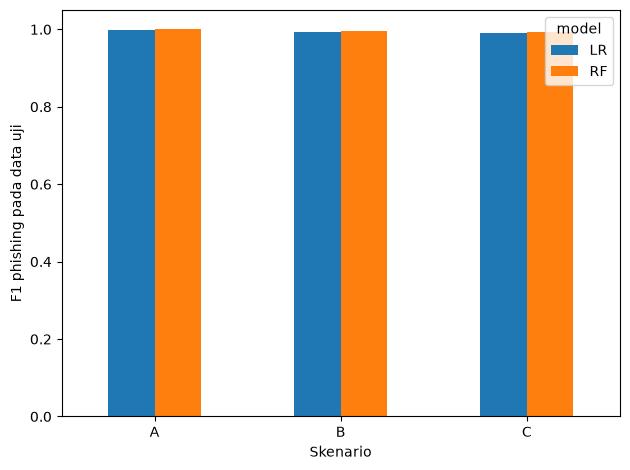

In [4]:
display(main[["model", "skenario", "ambang", "val_f1", "uji_f1", "uji_precision",
              "uji_recall", "uji_fpr", "uji_roc_auc", "uji_tp", "uji_fn", "uji_fp",
              "uji_tn", "uji_batch_ms"]].round(5))
display(weighted[["model", "skenario", "ambang", "val_fpr", "val_recall", "uji_kelompok_min",
                  "uji_recall_min", "uji_recall", "uji_fpr"]].round(5))

def differences(table, comparisons, columns):
    rows = []
    for name, subset in table.groupby("model"):
        values = subset.set_index("skenario")[columns]
        for later, earlier in comparisons:
            delta = values.loc[later] - values.loc[earlier]
            rows.append(dict(model=name, perbandingan=f"{later} - {earlier}", **delta.to_dict()))
    return pd.DataFrame(rows)

deltas = {
    "selisih_utama": differences(main, [("B", "A"), ("C", "B")], ["uji_f1", "uji_recall", "uji_fpr"]),
    "selisih_pembobotan": differences(weighted, [("bobot_struktur", "bobot_kelas")],
                                     ["uji_recall_min", "uji_recall", "uji_fpr"]),
}
for filename, table in deltas.items():
    table.to_csv(OUT / f"{filename}.csv", index=False)
    display(table.round(5))

ax = main.pivot(index="skenario", columns="model", values="uji_f1").plot.bar(rot=0)
ax.set(xlabel="Skenario", ylabel="F1 phishing pada data uji", ylim=(0, 1.05))
plt.tight_layout()
plt.show()